# Quantum Fourier Transform Arithmetic and Modular Exponentiation

This notebook constructs arithmetic circuits using the **quantum Fourier transform (QFT)**, from constant addition through modular multiplication and modular exponentiation. It includes a second implementation based on Qiskit's `DraperQFTAdder`, then compares circuit resources with the ripple-carry approaches in [`modexp.ipynb`](modexp.ipynb).

### Contents

1. Construct constant addition with QFT phase rotations.
2. Make modular addition reversible, including underflow detection and cleanup.
3. Build modular multiply-accumulate and modular multiplication operations.
4. Compose controlled modular multiplication into modular exponentiation.
5. Compare phase-based arithmetic with the `DraperQFTAdder` variant.
6. Measure and compare logical gate counts, circuit depth, and qubits.

### Measurement methodology and scope

- Example results are verified using statevector or circuit simulations for selected small inputs.
- Arithmetic circuits are decomposed into the `u` and `cx` basis at `optimization_level=0` for resource comparisons. Counts can change with Qiskit versions and synthesis choices.
- The benchmark omits input-state preparation, hardware routing, noise, and quantum error correction.
- Structural asymptotic expressions are **upper bounds for the particular construction**, not hardware-time predictions or claims that one architecture is universally superior.
- The comparison uses separately recorded results from `modexp.ipynb`; the arithmetic benchmarks are connected by reference, not by importing the other notebook.

## Shared functions

The first cell defines QFT operations, phase shifts, validation helpers, and a function for presenting measured results. Execute the notebook sequentially.

In [42]:
import math
from functools import lru_cache
import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import QFTGate, DraperQFTAdder
from qiskit.quantum_info import Statevector
from IPython.display import display, Markdown

def register_width(N):
    """Number of qubits needed for residues 0..N-1 (N >= 2)."""
    if not isinstance(N, int) or isinstance(N, bool) or N < 2:
        raise ValueError('N must be an integer >= 2')
    return (N - 1).bit_length()


def ordinary_add_width(a, k):
    """Choose ordinary-adder width dynamically, WITHOUT arithmetic wraparound."""
    if not isinstance(a, int) or not isinstance(k, int):
        raise ValueError('a and k must be integers')
    if a < 0 or a + k < 0:
        raise ValueError('ordinary addition requires a >= 0 and a + k >= 0')
    return max(1, a.bit_length(), abs(k).bit_length(), (a + k).bit_length())


def prepare_number(qc, qubits, number):
    if not isinstance(number, int) or not (0 <= number < (1 << len(qubits))):
        raise ValueError('Number must be a nonnegative integer fitting the register')
    for i, q in enumerate(qubits):
        if (number >> i) & 1:
            qc.x(q)


def verify_quantum_output(qc, expected, label='', atol=1e-7):
    """Verify all output and scratch qubits for basis or superposition inputs.

    expected is either an integer basis index or {basis_index: amplitude}.
    Returns (actual basis index, probability), or (description, fidelity).
    """
    state = Statevector.from_instruction(qc).data
    if isinstance(expected, (int, np.integer)) and not isinstance(expected, (bool, np.bool_)):
        if not 0 <= expected < len(state):
            raise AssertionError(f'{label}: expected basis index is outside circuit')
        probabilities = np.abs(state)**2
        probability = float(probabilities[expected])
        actual = int(np.argmax(probabilities))
        assert abs(probability-1) < atol, (
            f'{label}: expected |{expected}>, most likely |{actual}>, P={probability:.9f}')
        return actual, probability
    if not isinstance(expected, dict):
        raise TypeError('expected must be an integer index or dict of amplitudes')
    target = np.zeros_like(state)
    for index, amplitude in expected.items():
        if not isinstance(index, int) or not 0 <= index < len(state):
            raise ValueError(f'{label}: basis index outside circuit')
        target[index] = amplitude
    assert np.isclose(np.linalg.norm(target), 1, atol=atol), f'{label}: expected state is unnormalized'
    overlap = np.vdot(target, state)
    fidelity = float(abs(overlap)**2)
    assert fidelity >= 1-atol, f'{label}: coherence/ancilla fidelity {fidelity:.8f}'
    aligned = state * np.exp(-1j*np.angle(overlap))
    assert np.allclose(aligned, target, atol=atol), f'{label}: relative phases differ'
    return 'Full state matched', fidelity


def verified_superposition_states(qc, expected_amplitudes, registers, label=''):
    """Verify the full state, then display expected AND simulated kets.

    `registers` is [(name, little_endian_qubit_indices), ...]. Only named
    data/control registers are printed; the full-state fidelity test also
    checks that omitted work, carry, flag and scratch qubits are reset.
    The examples below each contain two equal-weight basis branches.
    A physically irrelevant global phase is removed for display.
    """
    _, fidelity = verify_quantum_output(qc, expected_amplitudes, label)
    expected = np.zeros(1 << qc.num_qubits, dtype=complex)
    for index, amplitude in expected_amplitudes.items():
        expected[index] = amplitude
    actual = np.array(Statevector.from_instruction(qc).data)
    # Align actual to expected; never interpret a global phase as a difference.
    actual *= np.exp(-1j * np.angle(np.vdot(expected, actual)))
    indices = list(expected_amplitudes)  # preserve off/on or a=0/1 order

    def render(state):
        if len(indices) != 2:
            raise ValueError('This ket formatter expects a two-branch superposition')
        if not all(np.isclose(abs(state[i]), 1/math.sqrt(2), atol=1e-6) for i in indices):
            raise AssertionError(f'{label}: branch magnitudes are not 1/sqrt(2)')

        def ket(index):
            pieces = []
            for name, positions in registers:
                number = sum(((index >> q) & 1) << bit for bit, q in enumerate(positions))
                suffix = ('_{' + name + '}') if name else ''
                pieces.append(r'\lvert ' + str(number) + r'\rangle' + suffix)
            return ''.join(pieces)

        ratio = state[indices[1]] / state[indices[0]]
        if np.isclose(ratio, 1, atol=1e-6):
            joining = '+'
        elif np.isclose(ratio, -1, atol=1e-6):
            joining = '-'
        else:
            angle = np.angle(ratio)
            joining = rf'+e^{{i({angle:.4f})}}'
        return r'$\frac{' + ket(indices[0]) + joining + ket(indices[1]) + r'}{\sqrt{2}}$'

    return render(expected), render(actual), fidelity


def show_table(title, headings, rows, *, item_name='rows', note=None):
    """General Markdown table renderer: suitable for tests AND circuit resources."""
    assert all(len(row) == len(headings) for row in rows), 'Table width mismatch'
    safe = lambda value: str(value).replace('|', r'\|').replace('\n', ' ')
    markdown_table = '\n'.join([
        '| ' + ' | '.join(map(safe, headings)) + ' |',
        '| ' + ' | '.join(['---'] * len(headings)) + ' |',
        *['| ' + ' | '.join(map(safe, row)) + ' |' for row in rows],
    ])
    header = f'**{title}**  -  {len(rows)} {item_name}'
    if item_name == 'quantum verification cases' and note is None:
        note = ('P is basis-state probability; F is full-state superposition fidelity. '
                'Checks include all work and flag qubits.')
    footer = f'\n\n*{note}*' if note else ''
    display(Markdown(header + '\n\n' + markdown_table + footer))


def expect_value_error(label, action):
    """Silently verify ValueError is raised; fail if the input is accepted."""
    try:
        action()
    except ValueError:
        return
    raise AssertionError(f'{label}: invalid input was not rejected')


def check_residue(value, N, name):
    if not isinstance(value, int) or not (0 <= value < N):
        raise ValueError(f'{name} must be an integer satisfying 0 <= {name} < N')


## Step 1a. QFT-based constant addition

Rather than propagating a carry bit, QFT-based addition applies phase rotations to the Fourier-basis representation of the target register:

$$\operatorname{Add}(k)=\operatorname{QFT}^{-1}\,\operatorname{Sum}(k)\,\operatorname{QFT}.$$

On an $m$-qubit register, a phase layer implements constant addition using rotations of the form

$$\operatorname{P}\left(\frac{2\pi k}{2^{m-j}}\right),$$

with angles determined by the wire index $j$. The code constructs the operation, displays a circuit example, and checks the resulting state.

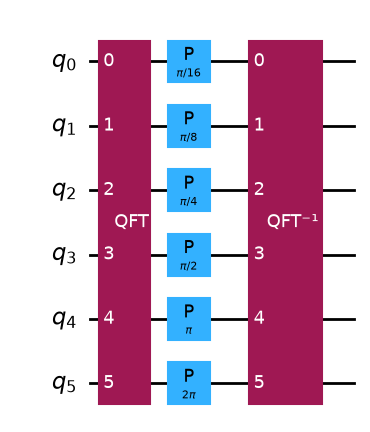

**Step 1(a): ordinary QFT addition**  -  11 quantum verification cases

| Case | a | k | n qubits | Expected a+k | Actual | Probability / Fidelity |
| --- | --- | --- | --- | --- | --- | --- |
| zero plus zero | 0 | 0 | 1 | 0 | 0 | 1.000000 |
| add to zero | 0 | 1 | 1 | 1 | 1 | 1.000000 |
| identity | 7 | 0 | 3 | 7 | 7 | 1.000000 |
| ordinary sum | 3 | 2 | 3 | 5 | 5 | 1.000000 |
| carry expands width | 7 | 1 | 4 | 8 | 8 | 1.000000 |
| larger carry | 31 | 1 | 6 | 32 | 32 | 1.000000 |
| negative shift | 7 | -3 | 3 | 4 | 4 | 1.000000 |
| subtract to zero | 8 | -8 | 4 | 0 | 0 | 1.000000 |
| subtract one | 1 | -1 | 1 | 0 | 0 | 1.000000 |
| larger sum | 14 | 13 | 5 | 27 | 27 | 1.000000 |
| superposed input | (\|0>+\|1>)/√2 | 2 | 2 | $\frac{\lvert 2\rangle+\lvert 3\rangle}{\sqrt{2}}$ | $\frac{\lvert 2\rangle+\lvert 3\rangle}{\sqrt{2}}$ | F=1.000000 |

*P is basis-state probability; F is full-state superposition fidelity. Checks include all work and flag qubits.*

In [46]:
@lru_cache(maxsize=None)
def qft_block(width, inverse=False):
    # QFTGate is the modern Qiskit QFT operation, including final bit-reversal swaps.
    # Its inverse is the inverse-QFT gate; no deprecated QFT circuit is used.
    gate = QFTGate(width)
    if inverse:
        gate = gate.inverse()
    gate.label = 'QFT⁻¹' if inverse else 'QFT'
    return gate


def apply_qft(qc, target, inverse=False):
    qc.append(qft_block(len(target), inverse), list(target))


def sum_k_in_fourier_basis(qc, target, k, controls=()):
    """Implement the phase-addition Sum(k) block.

    target is little-endian; controls may have length 0, 1 or 2.
    """
    controls = list(controls)
    width = len(target)
    for j, qubit in enumerate(target):
        angle = 2 * np.pi * k / (1 << (width - j))
        if not controls:
            qc.p(angle, qubit)
        elif len(controls) == 1:
            qc.cp(angle, controls[0], qubit)
        else:
            qc.mcp(angle, controls, qubit)


def qft_constant_add(qc, target, k, controls=()):
    apply_qft(qc, target)
    sum_k_in_fourier_basis(qc, target, k, controls)
    apply_qft(qc, target, inverse=True)


# A dynamically sized Step 1(a) adder; no modular reduction appears in this table.
def make_plain_add_example(a, k):
    n = ordinary_add_width(a, k)
    qc = QuantumCircuit(n)
    prepare_number(qc, list(range(n)), a)
    qft_constant_add(qc, list(range(n)), k)
    return qc, n


# Normal, identity, carry, largest input, exact cancellation, and signed addition.
plain_cases = [
    ('zero plus zero', 0, 0), ('add to zero', 0, 1),
    ('identity', 7, 0), ('ordinary sum', 3, 2),
    ('carry expands width', 7, 1), ('larger carry', 31, 1),
    ('negative shift', 7, -3), ('subtract to zero', 8, -8),
    ('subtract one', 1, -1), ('larger sum', 14, 13),
]
adder_rows = []
for label, a, k in plain_cases:
    qc, n = make_plain_add_example(a, k)
    expected = a + k
    actual, prob = verify_quantum_output(qc, expected, f'Step 1(a) {label}: {a}+{k}')
    adder_rows.append([label, a, k, n, expected, actual, f'{prob:.6f}'])

expect_value_error('negative initial value', lambda: make_plain_add_example(-1, 3))
expect_value_error('negative mathematical result', lambda: make_plain_add_example(1, -2))
expect_value_error('non-integer constant', lambda: make_plain_add_example(3, 1.5))
expect_value_error('value exceeds specified register',
                   lambda: prepare_number(QuantumCircuit(2), [0, 1], 4))

# Display the QFT adder itself: input preparation is only for numerical tests.
add_diagram_width = ordinary_add_width(20, 21)
qft_add_diagram = QuantumCircuit(add_diagram_width)
qft_constant_add(qft_add_diagram, list(range(add_diagram_width)), 2)
display(qft_add_diagram.draw('mpl', fold=-1))
# Coherent superposition: include its full-state check in the arithmetic table.
qc = QuantumCircuit(2)
qc.h(0)
qft_constant_add(qc, [0, 1], 2)
r = 1 / math.sqrt(2)
expected_state, actual_state, fidelity = verified_superposition_states(
    qc, {2:r, 3:r}, [('', [0, 1])], 'Step 1(a): superposed input')
adder_rows.append(['superposed input', '(|0>+|1>)/√2', 2, 2,
                   expected_state, actual_state, f'F={fidelity:.6f}'])
show_table('Step 1(a): ordinary QFT addition',
           ['Case', 'a', 'k', 'n qubits', 'Expected a+k', 'Actual', 'Probability / Fidelity'],
           adder_rows, item_name='quantum verification cases')


## Step 1b. Reversible modular addition

Construct a modular constant adder on valid inputs, using an extended target register and one underflow flag:

$$|0\rangle|a\rangle|0\rangle\longrightarrow|0\rangle|(a+k)\bmod N\rangle|0\rangle.$$

The implementation follows these stages:

1. Enter the Fourier basis, add $k$, subtract $N$, and return to the computational basis.
2. Copy the sign/underflow information from the extended target into a flag qubit.
3. Restore $N$ conditionally, reverse the initial addition temporarily, and uncompute the flag.
4. Reapply the addition and return from the Fourier basis.

The target's extra most-significant bit and the separate flag are required by this construction. The code verifies the arithmetic and checks that temporary bits are restored.

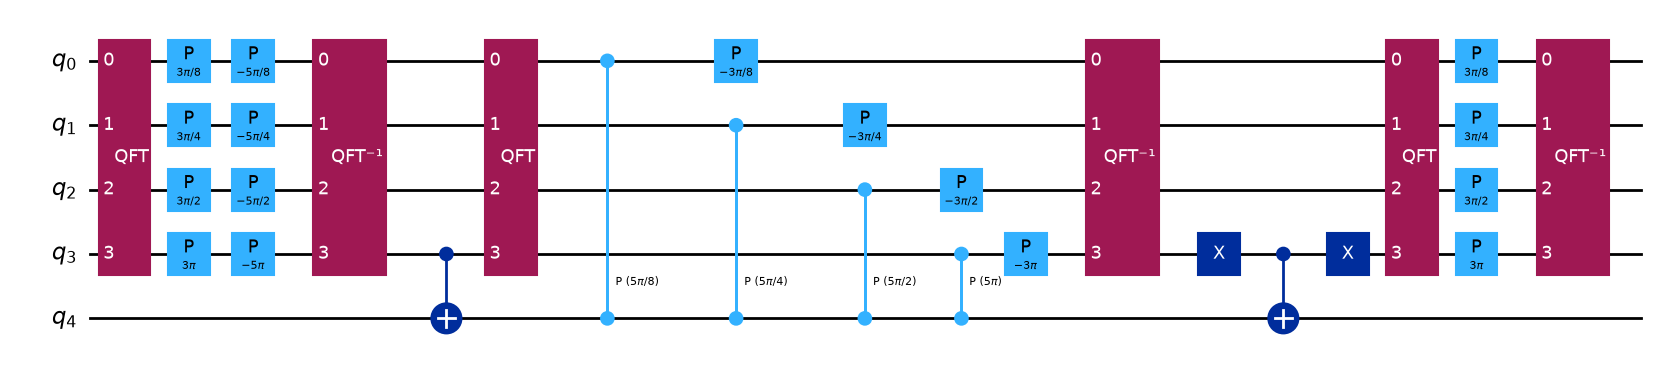

**Step 1(b): reversible modular adder**  -  19 quantum verification cases

| Case | a | k | N | Control bits | Expected | Actual | Probability / Fidelity |
| --- | --- | --- | --- | --- | --- | --- | --- |
| zero + zero | 0 | 0 | 2 |  -  | 0 | 0 | 1.000000 |
| smallest modulus | 1 | 1 | 2 |  -  | 0 | 0 | 1.000000 |
| no wrap | 0 | 1 | 3 |  -  | 1 | 1 | 1.000000 |
| exact modulus | 2 | 1 | 3 |  -  | 0 | 0 | 1.000000 |
| one below zero | 0 | -1 | 3 |  -  | 2 | 2 | 1.000000 |
| zero shift | 4 | 0 | 5 |  -  | 4 | 4 | 1.000000 |
| ordinary in range | 1 | 2 | 5 |  -  | 3 | 3 | 1.000000 |
| wrap at N | 4 | 1 | 5 |  -  | 0 | 0 | 1.000000 |
| wrap past N | 4 | 4 | 5 |  -  | 3 | 3 | 1.000000 |
| k > N | 2 | 7 | 5 |  -  | 4 | 4 | 1.000000 |
| negative k | 1 | -3 | 5 |  -  | 3 | 3 | 1.000000 |
| identity control | 4 | 3 | 5 | 0 | 4 | 4 | 1.000000 |
| active control | 4 | 3 | 5 | 1 | 2 | 2 | 1.000000 |
| two controls off | 4 | 3 | 5 | 10 | 4 | 4 | 1.000000 |
| two controls on | 4 | 3 | 5 | 11 | 2 | 2 | 1.000000 |
| nonpower-of-two | 6 | 2 | 7 |  -  | 1 | 1 | 1.000000 |
| power-of-two N | 7 | 1 | 8 |  -  | 0 | 0 | 1.000000 |
| negative at N=8 | 0 | -1 | 8 |  -  | 7 | 7 | 1.000000 |
| superposed control | 2 | 2 | 3 | \|+> | $\frac{\lvert 2\rangle_{a}\lvert 0\rangle_{c}+\lvert 1\rangle_{a}\lvert 1\rangle_{c}}{\sqrt{2}}$ | $\frac{\lvert 2\rangle_{a}\lvert 0\rangle_{c}+\lvert 1\rangle_{a}\lvert 1\rangle_{c}}{\sqrt{2}}$ | F=1.000000 |

*P is basis-state probability; F is full-state superposition fidelity. Checks include all work and flag qubits.*

In [47]:
def apply_modular_adder_qft(qc, target, flag, k, N, controls=()):
    """QFT modular adder, on valid inputs 0 <= target < N.

    target includes n low bits and one initially-zero overflow bit.
    flag starts/ends in |0>. controls: zero, one, or two qubits.
    """
    target = list(target)
    controls = list(controls)
    n = register_width(N)
    if len(target) != n+1:
        raise ValueError(f'target must have {n+1} qubits, got {len(target)}')
    k %= N
    high = target[-1]

    apply_qft(qc, target)
    sum_k_in_fourier_basis(qc, target, k, controls)
    sum_k_in_fourier_basis(qc, target, -N)
    apply_qft(qc, target, inverse=True)

    qc.cx(high, flag)                             # store underflow

    apply_qft(qc, target)
    sum_k_in_fourier_basis(qc, target, N, [flag]) # correct underflow
    sum_k_in_fourier_basis(qc, target, -k, controls)
    apply_qft(qc, target, inverse=True)

    qc.x(high)            # open-control CNOT on high -> flag
    qc.cx(high, flag)     # clear the auxiliary flag
    qc.x(high)

    apply_qft(qc, target)
    sum_k_in_fourier_basis(qc, target, k, controls)
    apply_qft(qc, target, inverse=True)

def make_modular_add_example(a, k, N, bits=None):
    """Prepare a valid computational-basis input for the modular adder."""
    n = register_width(N)
    check_residue(a, N, 'a')
    if bits is not None and (len(bits) > 2 or any(bit not in (0,1) for bit in bits)):
        raise ValueError('control bits must have length 0..2 and values 0 or 1')
    m = n + 1
    ctrl_bits = [] if bits is None else list(bits)
    qc = QuantumCircuit(m + 1 + len(ctrl_bits))
    target = list(range(m))
    flag = m
    control_positions = list(range(m+1, qc.num_qubits))
    prepare_number(qc, target, a)
    for bit, qubit in zip(ctrl_bits, control_positions):
        if bit:
            qc.x(qubit)
    apply_modular_adder_qft(qc, target, flag, k, N, control_positions)
    return qc, control_positions


# Boundary coverage, multiple moduli (including N=2 and powers of two),
# negative and over-modulus constants, inactive controls, and two controls.
# Each case is (description, N, a, k, control bits); None means uncontrolled.
modadd_cases = [
    ('zero + zero',      2, 0, 0, None),
    ('smallest modulus', 2, 1, 1, None),
    ('no wrap',          3, 0, 1, None),
    ('exact modulus',    3, 2, 1, None),
    ('one below zero',   3, 0, -1, None),
    ('zero shift',       5, 4, 0, None),
    ('ordinary in range',5, 1, 2, None),
    ('wrap at N',        5, 4, 1, None),
    ('wrap past N',      5, 4, 4, None),
    ('k > N',            5, 2, 7, None),
    ('negative k',       5, 1, -3, None),
    ('identity control', 5, 4, 3, (0,)),
    ('active control',   5, 4, 3, (1,)),
    ('two controls off', 5, 4, 3, (1, 0)),
    ('two controls on',  5, 4, 3, (1, 1)),
    ('nonpower-of-two',  7, 6, 2, None),
    ('power-of-two N',   8, 7, 1, None),
    ('negative at N=8', 8, 0, -1, None),
]
modular_add_rows = []
for label, N, a, k, bits in modadd_cases:
    n = register_width(N)
    m = n + 1
    control_bits = [] if bits is None else list(bits)
    qc, control_positions = make_modular_add_example(a, k, N, bits)
    enabled = all(control_bits)  # all([]) is True for unconditional operation
    expected = (a + k) % N if enabled else a
    expected_index = expected | sum(bit << qubit for bit, qubit in zip(control_bits, control_positions))
    actual, prob = verify_quantum_output(qc, expected_index, f'Step 1(b): {label}')
    observed = actual & ((1 << n) - 1)
    modular_add_rows.append([label, a, k, N,
                             ' - ' if bits is None else ''.join(map(str, bits)),
                             expected, observed, f'{prob:.6f}'])

expect_value_error('N=1 has no valid width', lambda: register_width(1))
expect_value_error('negative N', lambda: register_width(-5))
expect_value_error('non-integer N', lambda: register_width(5.5))
expect_value_error('input a >= N', lambda: make_modular_add_example(5, 2, 5))
expect_value_error('incorrect register width',
                   lambda: apply_modular_adder_qft(QuantumCircuit(3),[0],1,1,5))
expect_value_error('invalid control bits',
                   lambda: make_modular_add_example(2,1,5,(2,)))

# Display only MODADD(3,5). The test input |4> is prepared separately.
N_modadd_diagram, k_modadd_diagram = 5, 3
m_modadd_diagram = register_width(N_modadd_diagram) + 1
modadd_diagram = QuantumCircuit(m_modadd_diagram + 1)
apply_modular_adder_qft(modadd_diagram, list(range(m_modadd_diagram)),
                        m_modadd_diagram, k_modadd_diagram, N_modadd_diagram)
display(modadd_diagram.draw('mpl', fold=-1))
# Superposed control: both off/on branches must remain coherent.
N, a, k = 3, 2, 2
width = register_width(N) + 1
qc = QuantumCircuit(width+2)
prepare_number(qc, list(range(width)), a)
control = width+1
qc.h(control)
apply_modular_adder_qft(qc, list(range(width)), width, k, N, [control])
r = 1/math.sqrt(2)
expected_state, actual_state, fidelity = verified_superposition_states(
    qc, {a:r, ((a+k)%N) | (1<<control):r},
    [('a', list(range(register_width(N)))), ('c', [control])],
    'Step 1(b): superposed control')
modular_add_rows.append(['superposed control', a, k, N, '|+>',
                         expected_state, actual_state, f'F={fidelity:.6f}'])

# Exhaustive small-domain validation, including inactive controls and cleanup.
small_basis_checks=0
for N in (3, 5):
    for a in range(N):
        for k in range(N):
            for bit in (0,1):
                circuit,control_indices=make_modular_add_example(a,k,N,(bit,))
                expected=(a+k)%N if bit else a
                expected_full=expected | (bit<<control_indices[0])
                verify_quantum_output(circuit,expected_full,
                                    f'exhaustive N={N},a={a},k={k},control={bit}')
                small_basis_checks+=1
show_table('Step 1(b): reversible modular adder',
           ['Case', 'a', 'k', 'N', 'Control bits', 'Expected', 'Actual', 'Probability / Fidelity'],
           modular_add_rows, item_name='quantum verification cases')


## Draper-adder utility

This helper implements signed, classical-constant shifts using Qiskit's `DraperQFTAdder`. A reusable constant register is initialized and uncomputed around each operation, allowing the later modular-arithmetic stages to use the built-in adder rather than explicit phase layers.

In [48]:
def apply_draper_constant_shift(qc, target, constant_register, value, controls=()):
    """Add a classical signed constant via Qiskit's DraperQFTAdder.

    The constant register is prepared and unprepared, remaining |0>.
    The built-in adder's first input is the constant, second is the target.
    """
    target = list(target)
    constant_register = list(constant_register)
    controls = list(controls)
    m = len(target)
    assert len(constant_register) == m
    constant = value % (1 << m)

    prepare_number(qc, constant_register, constant)
    builtin = DraperQFTAdder(num_state_qubits=m, kind='fixed').to_gate(label=f'DRAPERADD({m})')
    if controls:
        controlled_add = builtin.control(num_ctrl_qubits=len(controls))
        controlled_add.label = f'C{len(controls)}-DRAPERADD({m})'
        qc.append(controlled_add, controls + constant_register + target)
    else:
        qc.append(builtin, constant_register + target)
    # X is self-inverse: reset constant scratch, without measuring it.
    prepare_number(qc, constant_register, constant)


def apply_modular_adder_draper(qc, target, flag, scratch, k, N, controls=()):
    """Same underflow / correction / cleanup algorithm using DraperQFTAdder."""
    target = list(target)
    controls = list(controls)
    n = register_width(N)
    if len(target) != n+1 or len(scratch) != n+1:
        raise ValueError('Draper target and scratch must each have n+1 qubits')
    k %= N
    high = target[-1]

    apply_draper_constant_shift(qc, target, scratch, k, controls)
    apply_draper_constant_shift(qc, target, scratch, -N)
    qc.cx(high, flag)

    apply_draper_constant_shift(qc, target, scratch, N, [flag])
    apply_draper_constant_shift(qc, target, scratch, -k, controls)

    qc.x(high)
    qc.cx(high, flag)
    qc.x(high)
    apply_draper_constant_shift(qc, target, scratch, k, controls)


@lru_cache(maxsize=None)
def modular_adder_gate(k, N, style='phase', control_count=1):
    n = register_width(N)
    assert 0 <= control_count <= 2
    m = n + 1
    extra_scratch = m if style == 'draper' else 0
    # Stable name also survives Qiskit's inverse-gate naming.
    block_name = f'MODADD({k % N},{N})'
    qc = QuantumCircuit(m + 1 + extra_scratch + control_count, name=block_name)
    target = list(range(m))
    flag = m
    scratch = list(range(m+1, m+1+extra_scratch))
    controls = list(range(m+1+extra_scratch, qc.num_qubits))

    if style == 'phase':
        apply_modular_adder_qft(qc, target, flag, k, N, controls)
    elif style == 'draper':
        apply_modular_adder_draper(qc, target, flag, scratch, k, N, controls)
    else:
        raise ValueError('style must be phase or draper')
    return qc.to_gate(label=block_name)


def mac_into(qc, a, b, extra, flag, k, N, style='phase',
             scratch=(), master_control=None, inverse=False):
    """Controlled sum of (k*2**i mod N) for each multiplier bit a_i.

    Follow Activity 6, p. 2: forward MAC traverses the displayed MSB
    through LSB order (i=n-1 down to i=0). Its inverse uses the exact
    reverse order (i=0 up to i=n-1), with each modular addition inverted.
    """
    n = register_width(N)
    assert len(a) == len(b) == n
    if style == 'draper':
        assert len(scratch) == n + 1
    else:
        assert len(scratch) == 0
    indices = range(n) if inverse else reversed(range(n))
    for i in indices:
        constant = (k * (1 << i)) % N
        ctrl = [a[i]] if master_control is None else [master_control, a[i]]
        gate = modular_adder_gate(constant, N, style, len(ctrl))
        if inverse:
            gate = gate.inverse()
            inverse_name = f'MODADD⁻¹({constant},{N})'
            gate.name = inverse_name  # use the visible inverse notation for the gate name and label
            gate.label = inverse_name
        qc.append(gate, list(b) + [extra, flag] + list(scratch) + ctrl)

## Step 2. Modular multiply-accumulate

The modular multiply-accumulate (MAC) operation preserves the input register and updates an accumulator:

$$\operatorname{MAC}(k,N):\quad|a\rangle|b\rangle\longmapsto|a\rangle|(b+ka)\bmod N\rangle.$$

Writing $a=\sum_{i=0}^{n-1}a_i2^i$ gives

$$ka\bmod N=\left(\sum_i a_i(k2^i\bmod N)\right)\bmod N.$$

Each bit $a_i$ controls a modular addition with a corresponding classically computed constant. The example tests the arithmetic on small registers.

**Step 2: modular multiply-accumulate**  -  13 quantum verification cases

| Case | a | b | k | N | Expected b / state | Actual b / state | Probability / Fidelity |
| --- | --- | --- | --- | --- | --- | --- | --- |
| all zeros | 0 | 0 | 0 | 2 | 0 | 0 | 1.000000 |
| zero multiplier | 0 | 2 | 2 | 3 | 2 | 2 | 1.000000 |
| identity k=0 | 2 | 1 | 0 | 3 | 1 | 1 | 1.000000 |
| ordinary MAC | 2 | 3 | 3 | 5 | 4 | 4 | 1.000000 |
| zero accumulator | 2 | 0 | 3 | 5 | 1 | 1 | 1.000000 |
| a=0 | 0 | 4 | 3 | 5 | 4 | 4 | 1.000000 |
| all max residues | 4 | 4 | 3 | 5 | 1 | 1 | 1.000000 |
| k > N | 4 | 2 | 7 | 5 | 0 | 0 | 1.000000 |
| negative k | 1 | 2 | -3 | 5 | 4 | 4 | 1.000000 |
| k multiple of N | 3 | 4 | 5 | 5 | 4 | 4 | 1.000000 |
| power-of-two N | 7 | 7 | 3 | 8 | 4 | 4 | 1.000000 |
| power-of-two wrap | 6 | 1 | 5 | 8 | 7 | 7 | 1.000000 |
| superposed source | $(\|0\rangle+\|1\rangle)/\sqrt{2}$ | 1 | 2 | 3 | $\frac{\lvert 0\rangle_{a}\lvert 1\rangle_{b}+\lvert 1\rangle_{a}\lvert 0\rangle_{b}}{\sqrt{2}}$ | $\frac{\lvert 0\rangle_{a}\lvert 1\rangle_{b}+\lvert 1\rangle_{a}\lvert 0\rangle_{b}}{\sqrt{2}}$ | F=1.000000 |

*P is basis-state probability; F is full-state superposition fidelity. Checks include all work and flag qubits.*

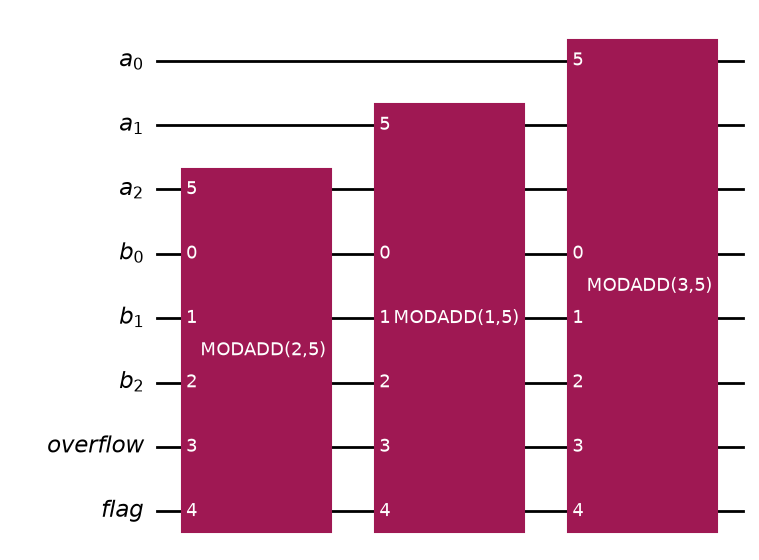

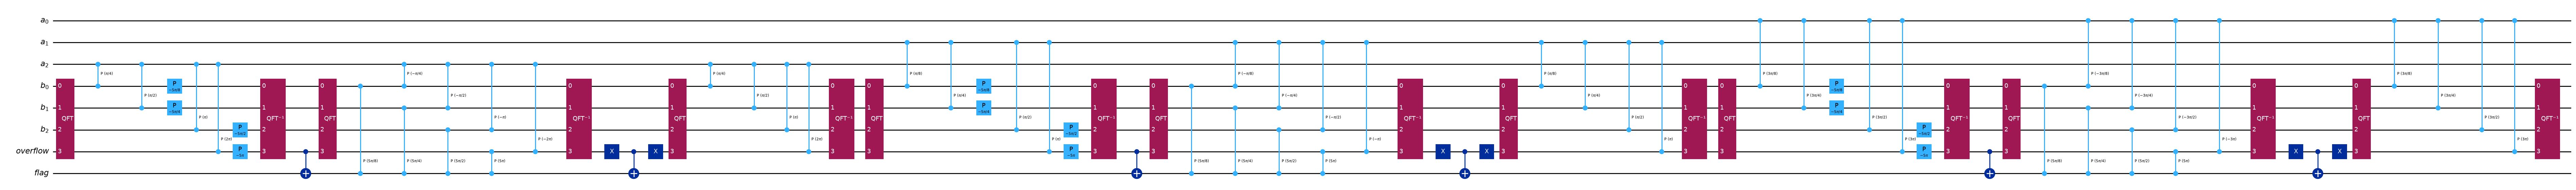

In [50]:

def make_mac_example(a_value, b_value, k, N, style='phase'):
    n = register_width(N)
    check_residue(a_value, N, 'a')
    check_residue(b_value, N, 'b')

    m = n + 1
    scratch_count = m if style == 'draper' else 0
    qc = QuantumCircuit(2*n + 2 + scratch_count)

    a = list(range(n))
    b = list(range(n, 2*n))
    extra, flag = 2*n, 2*n + 1
    scratch = list(range(2*n+2, qc.num_qubits))

    prepare_number(qc, a, a_value)
    prepare_number(qc, b, b_value)
    mac_into(qc, a, b, extra, flag, k, N, style, scratch)

    return qc


# Test cases: zero, maximum residues, negative/large k, wraparound.
mac_cases = [
    ('all zeros',          2, 0, 0, 0),
    ('zero multiplier',    3, 0, 2, 2),
    ('identity k=0',       3, 2, 1, 0),
    ('ordinary MAC',       5, 2, 3, 3),
    ('zero accumulator',   5, 2, 0, 3),
    ('a=0',                5, 0, 4, 3),
    ('all max residues',   5, 4, 4, 3),
    ('k > N',              5, 4, 2, 7),
    ('negative k',         5, 1, 2, -3),
    ('k multiple of N',    5, 3, 4, 5),
    ('power-of-two N',     8, 7, 7, 3),
    ('power-of-two wrap',  8, 6, 1, 5),
]

mac_rows = []

for label, N, a, b, k in mac_cases:
    n = register_width(N)
    qc = make_mac_example(a, b, k, N)

    expected_b = (b + k*a) % N
    expected_index = a | (expected_b << n)

    actual, prob = verify_quantum_output(
        qc, expected_index, f'Step 2: {label}'
    )

    actual_b = (actual >> n) & ((1 << n) - 1)

    mac_rows.append([
        label, a, b, k, N,
        expected_b, actual_b, f'{prob:.6f}'
    ])


# Invalid-input checks (retained without displaying tables).
expect_value_error(
    'a < 0', lambda: make_mac_example(-1, 1, 2, 5)
)
expect_value_error(
    'a >= N', lambda: make_mac_example(5, 1, 2, 5)
)
expect_value_error(
    'b >= N', lambda: make_mac_example(2, 5, 2, 5)
)
expect_value_error(
    'N < 2', lambda: make_mac_example(0, 0, 1, 1)
)


# Superposition test: MAC on a superposed source register.
# Full-state verification includes work and flag qubits.
N = 3
n = register_width(N)

qc = QuantumCircuit(2*n + 2)
qc.h(0)
qc.x(n)

mac_into(
    qc,
    list(range(n)),
    list(range(n, 2*n)),
    2*n,
    2*n+1,
    2,
    N
)

r = 1 / math.sqrt(2)

expected_state, actual_state, fidelity = verified_superposition_states(
    qc,
    {
        1 << n: r,
        1 | (((1+2) % N) << n): r
    },
    [
        ('a', list(range(n))),
        ('b', list(range(n, 2*n)))
    ],
    'Step 2: superposed source'
)

mac_rows.append([
    'superposed source',
    r'$(|0\rangle+|1\rangle)/\sqrt{2}$',
    1,
    2,
    N,
    expected_state,
    actual_state,
    f'F={fidelity:.6f}'
])


# Display arithmetic and superposition verification results.
show_table(
    'Step 2: modular multiply-accumulate',
    [
        'Case', 'a', 'b', 'k', 'N',
        'Expected b / state',
        'Actual b / state',
        'Probability / Fidelity'
    ],
    mac_rows,
    item_name='quantum verification cases'
)

from qiskit import QuantumRegister

N_mac_diagram, k_mac_diagram = 5, 3
n_mac_diagram = register_width(N_mac_diagram)

a_mac = QuantumRegister(n_mac_diagram, 'a')
b_mac = QuantumRegister(n_mac_diagram, 'b')
overflow_mac = QuantumRegister(1, 'overflow')
flag_mac = QuantumRegister(1, 'flag')

mac_diagram = QuantumCircuit(
    a_mac,
    b_mac,
    overflow_mac,
    flag_mac
)

mac_into(
    mac_diagram,
    list(a_mac),
    list(b_mac),
    overflow_mac[0],
    flag_mac[0],
    k_mac_diagram,
    N_mac_diagram
)

# Diagram 1: Compact MAC using controlled MODADD blocks.
display(mac_diagram.draw('mpl', fold=-1))

# Diagram 2: Expanded QFT-based implementation of the same MAC.
display(mac_diagram.decompose(reps=1).draw('mpl', fold=-1))


## Step 3. Modular multiplication from MAC blocks

Build a reversible multiplier by computing a modular product in a work register, swapping the registers, and uncomputing the original input using the modular inverse $k^{-1}\bmod N$:

$$|a\rangle|0\rangle\xrightarrow{\mathrm{MAC}(k,N)}|a\rangle|ka\bmod N\rangle$$
$$\xrightarrow{\mathrm{SWAP}}|ka\bmod N\rangle|a\rangle$$
$$\xrightarrow{\mathrm{MAC}(k^{-1},N)^{-1}}|ka\bmod N\rangle|0\rangle.$$

This requires $\gcd(k,N)=1$. The implementation also supports an external control for use in modular exponentiation.

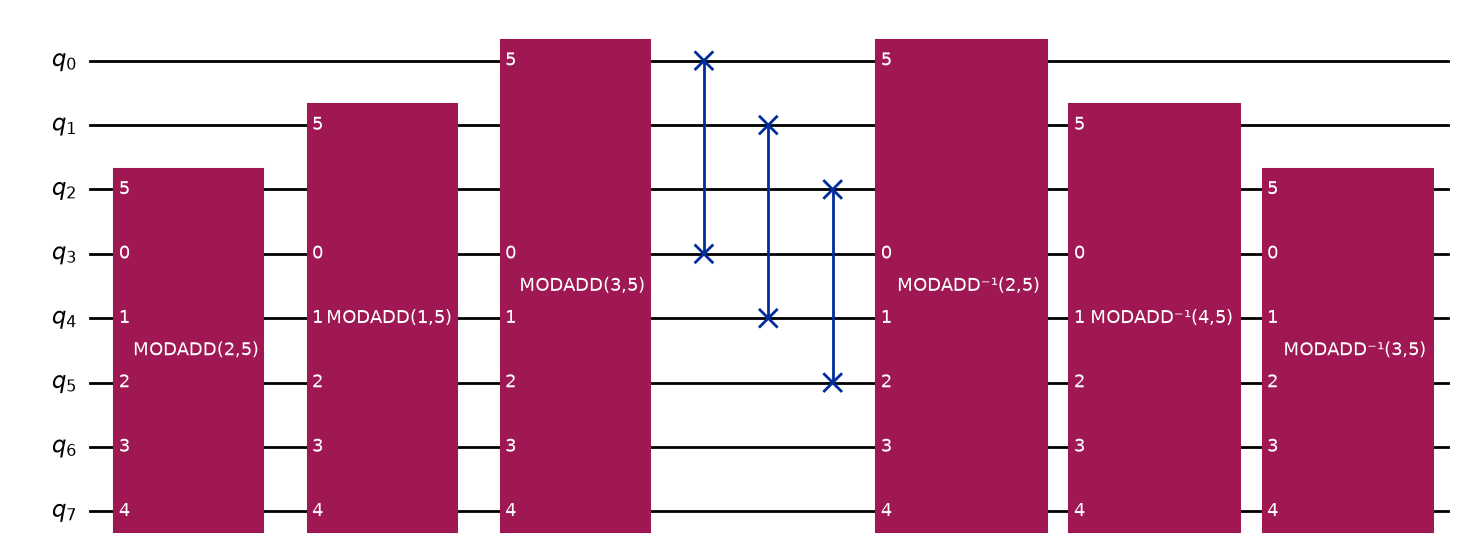

**Step 3: modular multiplier**  -  13 quantum verification cases

| Case | a | k | N | Control | Expected | Actual | Probability / Fidelity |
| --- | --- | --- | --- | --- | --- | --- | --- |
| zero | 0 | 2 | 3 |  -  | 0 | 0 | 1.000000 |
| identity k=1 | 2 | 1 | 3 |  -  | 2 | 2 | 1.000000 |
| small invertible | 2 | 2 | 3 |  -  | 1 | 1 | 1.000000 |
| ordinary product | 4 | 3 | 5 |  -  | 2 | 2 | 1.000000 |
| max residue | 4 | 4 | 5 |  -  | 1 | 1 | 1.000000 |
| multiplier=1 | 4 | 1 | 5 |  -  | 4 | 4 | 1.000000 |
| negative unit | 3 | -1 | 5 |  -  | 2 | 2 | 1.000000 |
| k > N | 3 | 7 | 5 |  -  | 1 | 1 | 1.000000 |
| controlled off | 4 | 3 | 5 | 0 | 4 | 4 | 1.000000 |
| controlled on | 4 | 3 | 5 | 1 | 2 | 2 | 1.000000 |
| another modulus | 6 | 3 | 7 |  -  | 4 | 4 | 1.000000 |
| power-of-two N | 7 | 5 | 8 |  -  | 3 | 3 | 1.000000 |
| superposed control | 1 | 2 | 3 | \|+> | $\frac{\lvert 1\rangle_{a}\lvert 0\rangle_{c}+\lvert 2\rangle_{a}\lvert 1\rangle_{c}}{\sqrt{2}}$ | $\frac{\lvert 1\rangle_{a}\lvert 0\rangle_{c}+\lvert 2\rangle_{a}\lvert 1\rangle_{c}}{\sqrt{2}}$ | F=1.000000 |

*P is basis-state probability; F is full-state superposition fidelity. Checks include all work and flag qubits.*

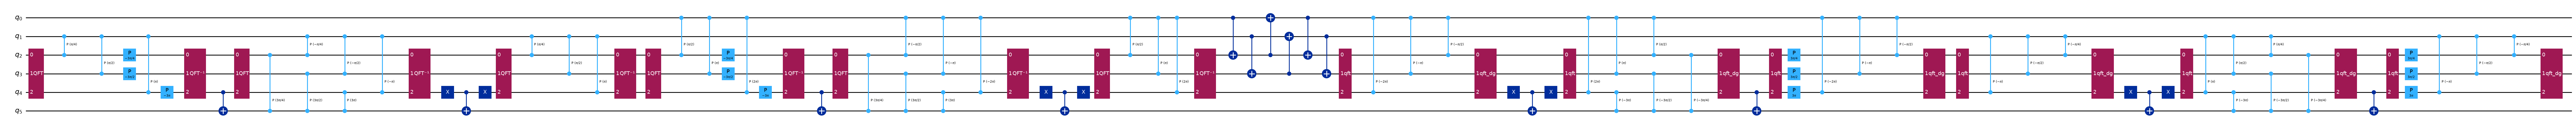

In [51]:
def multiply_into(qc, a, b, extra, flag, k, N, style='phase',
                  scratch=(), master_control=None):
    if math.gcd(k, N) != 1:
        raise ValueError('Mult(k,N) needs gcd(k,N)=1 so k has an inverse')
    inv = pow(k, -1, N)
    mac_into(qc, a, b, extra, flag, k, N, style, scratch, master_control)
    for qa, qb in zip(a, b):
        if master_control is None:
            qc.swap(qa, qb)
        else:
            qc.cswap(master_control, qa, qb)
    mac_into(qc, a, b, extra, flag, inv, N, style, scratch,
             master_control, inverse=True)


@lru_cache(maxsize=None)
def modular_multiplier_gate(k, N, style='phase', controlled=False):
    n = register_width(N)
    m = n + 1
    scratch_count = m if style == 'draper' else 0
    block_name = f'{"C" if controlled else ""}MULT({k % N},{N})'
    qc = QuantumCircuit(2*n + 2 + scratch_count + int(controlled), name=block_name)
    a = list(range(n))
    b = list(range(n, 2*n))
    extra, flag = 2*n, 2*n + 1
    scratch = list(range(2*n+2, 2*n+2+scratch_count))
    master = qc.num_qubits - 1 if controlled else None
    multiply_into(qc, a, b, extra, flag, k, N, style, scratch, master)
    return qc.to_gate(label=block_name)


def make_multiply_example(a_value, k, N, style='phase', control=None):
    n = register_width(N)
    check_residue(a_value, N, 'a')
    if control not in (None, 0, 1):
        raise ValueError('control must be None, 0, or 1')
    gate = modular_multiplier_gate(k, N, style, controlled=(control is not None))
    qc = QuantumCircuit(gate.num_qubits)
    prepare_number(qc, list(range(n)), a_value)
    if control == 1:
        qc.x(qc.num_qubits - 1)
    qc.append(gate, list(range(qc.num_qubits)))
    return qc

# 1, -1, and other invertible multipliers; zero/maximum a and controls.
mult_cases = [
    ('zero',               3, 2, 0, None),
    ('identity k=1',       3, 1, 2, None),
    ('small invertible',   3, 2, 2, None),
    ('ordinary product',   5, 3, 4, None),
    ('max residue',        5, 4, 4, None),
    ('multiplier=1',       5, 1, 4, None),
    ('negative unit',      5, -1, 3, None),
    ('k > N',              5, 7, 3, None),
    ('controlled off',     5, 3, 4, 0),
    ('controlled on',      5, 3, 4, 1),
    ('another modulus',    7, 3, 6, None),
    ('power-of-two N',     8, 5, 7, None),
]
mult_rows = []
for label, N, k, a, c in mult_cases:
    n = register_width(N)
    qc = make_multiply_example(a, k, N, control=c)
    expected = (k*a) % N if c is None or c == 1 else a
    expected_index = expected | ((c or 0) << (qc.num_qubits - 1))
    actual, prob = verify_quantum_output(qc, expected_index, f'Step 3: {label}')
    mult_rows.append([label, a, k, N, ' - ' if c is None else c,
                      expected, actual & ((1 << n)-1), f'{prob:.6f}'])

expect_value_error('noninvertible k=2 for N=4',
                   lambda: make_multiply_example(1, 2, 4))
expect_value_error('k=0 has no modular inverse',
                   lambda: make_multiply_example(1, 0, 5))
expect_value_error('invalid residue',
                   lambda: make_multiply_example(5, 3, 5))
expect_value_error('invalid control value',
                   lambda: make_multiply_example(1, 2, 3, control=2))

# Arithmetic-only MULT(3,5) diagram; no X gates to prepare |4>.
mult_diagram_gate = modular_multiplier_gate(3, 5)
mult_diagram = QuantumCircuit(mult_diagram_gate.num_qubits)
mult_diagram.append(mult_diagram_gate, list(range(mult_diagram.num_qubits)))
display(mult_diagram.decompose(reps=1).draw('mpl', fold=-1))
# Superposed control tests both multiplier branches and inverse-MAC cleanup.
N = 3
n = register_width(N)
gate = modular_multiplier_gate(2, N, controlled=True)
qc = QuantumCircuit(gate.num_qubits)
qc.x(0)
qc.h(qc.num_qubits-1)
qc.append(gate, list(range(qc.num_qubits)))
r = 1/math.sqrt(2)
expected_state, actual_state, fidelity = verified_superposition_states(
    qc, {1:r, 2 | (1<<(qc.num_qubits-1)):r},
    [('a', list(range(n))), ('c', [qc.num_qubits-1])],
    'Step 3: superposed control')
mult_rows.append(['superposed control', 1, 2, N, '|+>',
                  expected_state, actual_state, f'F={fidelity:.6f}'])
show_table('Step 3: modular multiplier',
           ['Case', 'a', 'k', 'N', 'Control', 'Expected', 'Actual', 'Probability / Fidelity'],
           mult_rows, item_name='quantum verification cases')

# More detail, on a smaller register: Mult -> modular adders -> QFT arithmetic.
# reps=2 expands both the Mult wrapper and its modular-adder gates.
# This display uses Qiskit's default Matplotlib gate styles (no custom colors).
small_mult_gate = modular_multiplier_gate(2, 3)
small_mult_for_diagram = QuantumCircuit(small_mult_gate.num_qubits)
small_mult_for_diagram.append(small_mult_gate, list(range(small_mult_for_diagram.num_qubits)))
display(small_mult_for_diagram.decompose(reps=2).draw('mpl', fold=-1))

## Step 4. Modular exponentiation

For $x=\sum_{j=0}^{n-1}x_j2^j$, modular exponentiation can be decomposed into controlled modular multiplications:

$$a^x\bmod N=\prod_{j=0}^{n-1}\left(a^{2^j}\bmod N\right)^{x_j}\bmod N.$$

Initialize the accumulator to $|1\rangle$ and the work register to $|0\rangle$. For each exponent bit, apply a controlled multiplier with constant $a^{2^j}\bmod N$. The construction restores its temporary work, extension, and flag registers between applications.

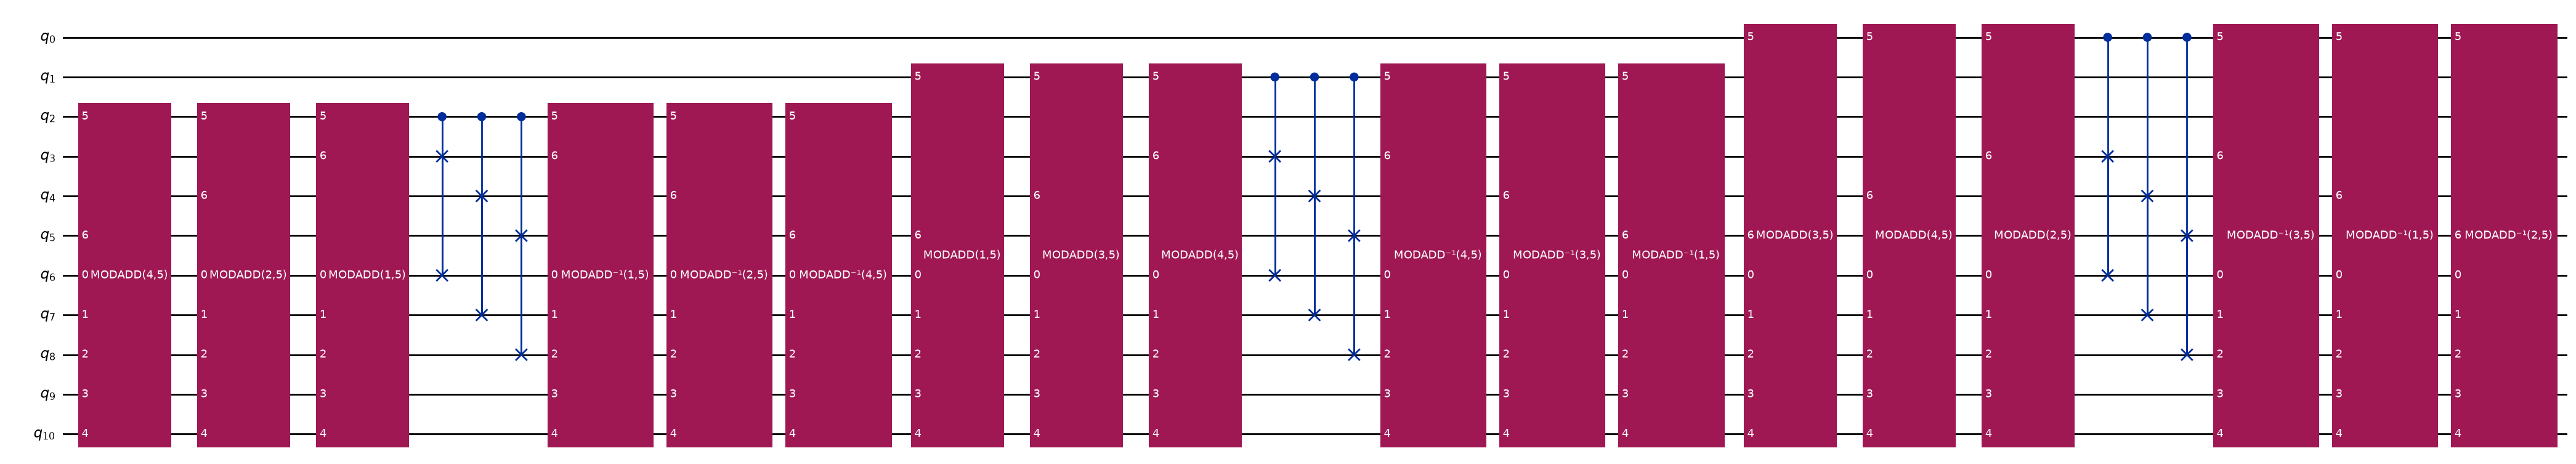

**Step 4: reversible modular exponentiation**  -  10 quantum verification cases

| Case | Base a | Exponent x | N | n bits | Expected | Actual | Probability / Fidelity |
| --- | --- | --- | --- | --- | --- | --- | --- |
| x=0 returns 1 | 2 | 0 | 3 | 2 | 1 | 1 | 1.000000 |
| x=1 | 2 | 1 | 3 | 2 | 2 | 2 | 1.000000 |
| x=2 | 2 | 2 | 3 | 2 | 1 | 1 | 1.000000 |
| max exponent n=2 | 2 | 3 | 3 | 2 | 2 | 2 | 1.000000 |
| base=1 | 1 | 7 | 5 | 3 | 1 | 1 | 1.000000 |
| regular case | 2 | 3 | 5 | 3 | 3 | 3 | 1.000000 |
| exponent even | 2 | 4 | 5 | 3 | 1 | 1 | 1.000000 |
| max exponent n=3 | 2 | 7 | 5 | 3 | 3 | 3 | 1.000000 |
| power-of-two N | 3 | 3 | 8 | 3 | 3 | 3 | 1.000000 |
| superposed exponent | 2 | \|+> | 3 | 2 | $\frac{\lvert 0\rangle_{x}\lvert 1\rangle_{y}+\lvert 1\rangle_{x}\lvert 2\rangle_{y}}{\sqrt{2}}$ | $\frac{\lvert 0\rangle_{x}\lvert 1\rangle_{y}+\lvert 1\rangle_{x}\lvert 2\rangle_{y}}{\sqrt{2}}$ | F=1.000000 |

*P is basis-state probability; F is full-state superposition fidelity. Checks include all work and flag qubits.*

In [52]:
def build_modular_exponentiation(base, N, exponent, style='phase', prepare=True):
    n = register_width(N)
    if not isinstance(base, int) or isinstance(base, bool):
        raise ValueError('base must be an integer')
    if not isinstance(exponent, int) or isinstance(exponent, bool):
        raise ValueError('exponent must be an integer')
    if math.gcd(base, N) != 1:
        raise ValueError('The modular multiplication construction requires gcd(base,N)=1')
    if not (0 <= exponent < (1 << n)):
        raise ValueError('Exponent must fit in n bits')

    scratch_count = n + 1 if style == 'draper' else 0
    # Layout: exponent x[n] | answer y[n] | work[n] | extension | flag | scratch[n+1]
    qc = QuantumCircuit(3*n + 2 + scratch_count)
    x = list(range(0, n))
    y = list(range(n, 2*n))
    work = list(range(2*n, 3*n))
    extra, flag = 3*n, 3*n+1
    scratch = list(range(3*n+2, qc.num_qubits))

    if prepare:
        prepare_number(qc, x, exponent)
        qc.x(y[0])             # example inputs only, excluded from resource counts

    for j in reversed(range(n)):
        factor = pow(base, 1 << j, N)
        gate = modular_multiplier_gate(factor, N, style, controlled=True)
        qc.append(gate, y + work + [extra, flag] + scratch + [x[j]])
    return qc


def verify_modexp(base, N, exponent, style='phase'):
    n = register_width(N)
    qc = build_modular_exponentiation(base, N, exponent, style)
    expected = pow(base, exponent, N)
    # All work and flag/scratch bits must be 0. Exponent is unchanged.
    expected_index = exponent | (expected << n)
    actual_index, probability = verify_quantum_output(
        qc, expected_index,
        f'ModExp[{style}]: {base}^{exponent} mod {N} = {expected}')
    actual_result = (actual_index >> n) & ((1 << n) - 1)
    return qc, expected, actual_result, probability

# Include exponent zero, exponent=1, repeated powers, maximum exponent,
# base=1, and a power-of-two modulus. Small N keeps statevector tests practical.
modexp_cases = [
    ('x=0 returns 1',     2, 3, 0),
    ('x=1',               2, 3, 1),
    ('x=2',               2, 3, 2),
    ('max exponent n=2',  2, 3, 3),
    ('base=1',            1, 5, 7),
    ('regular case',      2, 5, 3),
    ('exponent even',     2, 5, 4),
    ('max exponent n=3',  2, 5, 7),
    ('power-of-two N',    3, 8, 3),
]
modexp_rows = []
for label, base_value, modulus, exponent_value in modexp_cases:
    qc, expected, actual, prob = verify_modexp(base_value, modulus, exponent_value)
    modexp_rows.append([label, base_value, exponent_value, modulus, register_width(modulus),
                        expected, actual, f'{prob:.6f}'])

expect_value_error('base not coprime to N',
                   lambda: build_modular_exponentiation(2, 4, 1))
expect_value_error('exponent exceeds n qubits',
                   lambda: build_modular_exponentiation(2, 5, 8))
expect_value_error('negative exponent',
                   lambda: build_modular_exponentiation(2, 5, -1))
expect_value_error('N < 2',
                   lambda: build_modular_exponentiation(2, 1, 1))

# Arithmetic-only MODEXP; the initial |x>|1> is prepared in verification circuits.
modexp_diagram = build_modular_exponentiation(2, 5, 0, prepare=False)
display(modexp_diagram.decompose(reps=1).draw('mpl', fold=-1))
# A superposed exponent must retain the correct relative phase.
N = 3
n = register_width(N)
prep = QuantumCircuit(3*n+2)
prep.h(0)
prep.x(n)
prep.compose(build_modular_exponentiation(2, N, 0, prepare=False), inplace=True)
r = 1/math.sqrt(2)
expected_state, actual_state, fidelity = verified_superposition_states(
    prep, {1<<n:r, 1|(2<<n):r},
    [('x', list(range(n))), ('y', list(range(n, 2*n)))],
    'Step 4: superposed exponent')
modexp_rows.append(['superposed exponent', 2, '|+>', N, n,
                    expected_state, actual_state, f'F={fidelity:.6f}'])
show_table('Step 4: reversible modular exponentiation',
           ['Case', 'Base a', 'Exponent x', 'N', 'n bits', 'Expected', 'Actual', 'Probability / Fidelity'],
           modexp_rows, item_name='quantum verification cases')


## Step 5. `DraperQFTAdder` implementation

Repeat the arithmetic hierarchy using Qiskit's built-in `DraperQFTAdder` as the core addition operation. This creates an alternative to directly applying controlled phase shifts and requires an additional reusable constant register.

The tests cover constant addition, modular addition, modular MAC, modular multiplication, and a small modular exponentiation case. Larger controlled-adder examples become expensive to simulate and transpile, so this is a small-instance validation rather than a scaling experiment.

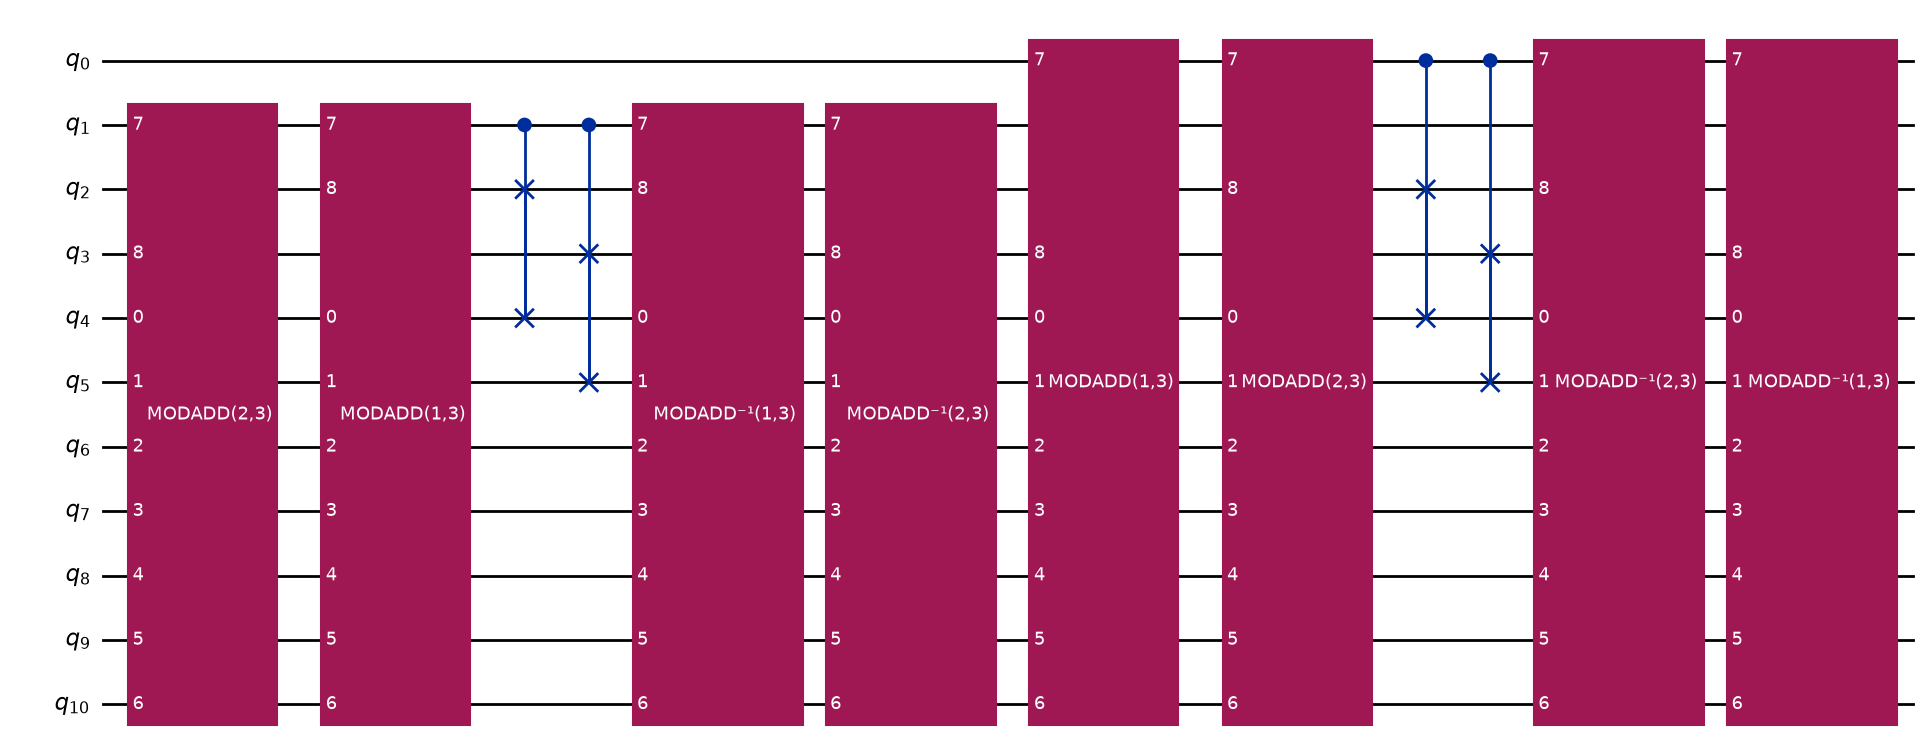

**Step 5: DraperQFTAdder modular arithmetic**  -  15 quantum verification cases

| Circuit | Case | Operation | Expected | Actual | Probability / Fidelity |
| --- | --- | --- | --- | --- | --- |
| MODADD | zero constant | (2+0) mod 3 | 2 | 2 | 1.000000 |
| MODADD | wraparound | (2+2) mod 3 | 1 | 1 | 1.000000 |
| MODADD | negative constant | (0+-1) mod 3 | 2 | 2 | 1.000000 |
| MODADD | power-of-two modulus | (3+1) mod 4 | 0 | 0 | 1.000000 |
| MAC | zero multiplier | (2+2*0) mod 3 | 2 | 2 | 1.000000 |
| MAC | nonzero accumulator | (1+2*2) mod 3 | 2 | 2 | 1.000000 |
| MAC | negative factor | (2+-1*2) mod 3 | 0 | 0 | 1.000000 |
| MULT | zero a | (0*2) mod 3 | 0 | 0 | 1.000000 |
| MULT | nontrivial product | (2*2) mod 3 | 1 | 1 | 1.000000 |
| MULT | disabled control | control=0 | 2 | 2 | 1.000000 |
| MODEXP | exponent zero | 2^0 mod 3 | 1 | 1 | 1.000000 |
| MODEXP | nonzero exponent | 2^2 mod 3 | 1 | 1 | 1.000000 |
| MODEXP | maximum exponent | 2^3 mod 3 | 2 | 2 | 1.000000 |
| MODADD | superposed control | a=2,k=2,N=3 | $\frac{\lvert 2\rangle_{a}\lvert 0\rangle_{c}+\lvert 1\rangle_{a}\lvert 1\rangle_{c}}{\sqrt{2}}$ | $\frac{\lvert 2\rangle_{a}\lvert 0\rangle_{c}+\lvert 1\rangle_{a}\lvert 1\rangle_{c}}{\sqrt{2}}$ | F=1.000000 |
| MODEXP | superposed exponent | 2^x mod 3 (x=0,1) | $\frac{\lvert 0\rangle_{x}\lvert 1\rangle_{y}+\lvert 1\rangle_{x}\lvert 2\rangle_{y}}{\sqrt{2}}$ | $\frac{\lvert 0\rangle_{x}\lvert 1\rangle_{y}+\lvert 1\rangle_{x}\lvert 2\rangle_{y}}{\sqrt{2}}$ | F=1.000000 |

*P is basis-state probability; F is full-state superposition fidelity. Checks include all work and flag qubits.*

In [53]:
# Step 5 explicitly tests all four Draper-based arithmetic building blocks.
# Keep its largest exponentiation tests at N=3 (n=2), since controlled
# DraperQFTAdder simulation becomes expensive for larger n.
draper_rows = []

# Built-in modular adder: identity, wrap, negative constant, and N=power of two.
for label, N, a, k in [
    ('zero constant', 3, 2, 0), ('wraparound', 3, 2, 2),
    ('negative constant', 3, 0, -1), ('power-of-two modulus', 4, 3, 1),
]:
    n = register_width(N)
    m = n+1
    qc = QuantumCircuit(2*m+1)
    prepare_number(qc, list(range(m)), a)
    apply_modular_adder_draper(qc, list(range(m)), m,
                               list(range(m+1, 2*m+1)), k, N)
    expected = (a+k)%N
    actual, prob = verify_quantum_output(qc, expected, f'Step 5 Draper modular adder {label}')
    draper_rows.append(['MODADD', label, f'({a}+{k}) mod {N}', expected,
                        actual & ((1<<n)-1), f'{prob:.6f}'])

# MAC, including zero multiplier and overflow.
for label, a, b, k, N in [
    ('zero multiplier', 0, 2, 2, 3),
    ('nonzero accumulator', 2, 1, 2, 3),
    ('negative factor', 2, 2, -1, 3),
]:
    n = register_width(N)
    qc = make_mac_example(a,b,k,N,style='draper')
    expected = (b + k*a)%N
    actual, prob = verify_quantum_output(qc, a | (expected << n), f'Step 5 Draper MAC {label}')
    draper_rows.append(['MAC', label, f'({b}+{k}*{a}) mod {N}', expected,
                        (actual>>n)&((1<<n)-1), f'{prob:.6f}'])

# Reversible multiplier and inactive control.
for label, a, k, N, control in [
    ('zero a', 0, 2, 3, None),
    ('nontrivial product', 2, 2, 3, None),
    ('disabled control', 2, 2, 3, 0),
]:
    n = register_width(N)
    qc = make_multiply_example(a,k,N,style='draper',control=control)
    expected = a if control == 0 else (a*k)%N
    expected_index = expected | ((control or 0) << (qc.num_qubits-1))
    actual, prob = verify_quantum_output(qc, expected_index, f'Step 5 Draper Mult {label}')
    draper_rows.append(['MULT', label, f'({a}*{k}) mod {N}' if control != 0 else 'control=0',
                        expected, actual&((1<<n)-1), f'{prob:.6f}'])

# Complete Draper-based modular exponentiation including both exponent extremes.
for label, x in [('exponent zero',0), ('nonzero exponent',2), ('maximum exponent',3)]:
    qc, expected, actual, prob = verify_modexp(2,3,x,style='draper')
    draper_rows.append(['MODEXP', label, f'2^{x} mod 3', expected, actual,
                        f'{prob:.6f}'])

expect_value_error('Draper noninvertible multiplier',
                   lambda: make_multiply_example(1,2,4,style='draper'))
expect_value_error('Draper noncoprime base',
                   lambda: build_modular_exponentiation(2,4,1,style='draper'))

# Same arithmetic-only presentation as Step 4: no input-preparation X gates.
modexp_draper_diagram = build_modular_exponentiation(
    2, 3, 0, style='draper', prepare=False)
assert modexp_draper_diagram.num_qubits == 4 * register_width(3) + 3
display(modexp_draper_diagram.decompose(reps=1).draw('mpl', fold=-1))
# Superposed Draper control and exponent, with scratch-qubit cleanup checks.
N = 3
n = register_width(N)
m = n + 1
qc = QuantumCircuit(2*m+2)
prepare_number(qc, list(range(m)), 2)
ctrl = qc.num_qubits-1
qc.h(ctrl)
apply_modular_adder_draper(qc, list(range(m)), m,
                           list(range(m+1,2*m+1)), 2, N, [ctrl])
r = 1/math.sqrt(2)
expected_state, actual_state, fidelity = verified_superposition_states(
    qc, {2:r, 1|(1<<ctrl):r},
    [('a', list(range(n))), ('c', [ctrl])],
    'Step 5: superposed Draper control')
draper_rows.append(['MODADD', 'superposed control', 'a=2,k=2,N=3',
                    expected_state, actual_state, f'F={fidelity:.6f}'])

prep = QuantumCircuit(4*n+3)
prep.h(0)
prep.x(n)
prep.compose(build_modular_exponentiation(2, N, 0, style='draper', prepare=False),
             inplace=True)
expected_state, actual_state, fidelity = verified_superposition_states(
    prep, {1<<n:r, 1|(2<<n):r},
    [('x', list(range(n))), ('y', list(range(n, 2*n)))],
    'Step 5: superposed Draper exponent')
draper_rows.append(['MODEXP', 'superposed exponent', '2^x mod 3 (x=0,1)',
                    expected_state, actual_state, f'F={fidelity:.6f}'])
show_table('Step 5: DraperQFTAdder modular arithmetic',
           ['Circuit', 'Case', 'Operation', 'Expected', 'Actual', 'Probability / Fidelity'],
           draper_rows, item_name='quantum verification cases')


## Step 6a. QFT arithmetic resource analysis

Let $n=\lceil\log_2 N\rceil$ be the data-register width and $m=n+1$ the extended
QFT target width. This is a **modulus-dependent** width, distinct from the input-
and-result-dependent width in Step 1(a). For $N\ge2$, compute $n=(N-1).\texttt{bit\_length()}$.

For an exact QFT decomposition on $m$ wires: there are $m$ Hadamards,
$m(m-1)/2$ controlled-phase rotations, and $\lfloor m/2\rfloor$ bit-reversal
SWAPs. The inverse QFT has the same structure. Each course-note
`Sum(k)` block uses $m$ phase rotations (each with at most two external controls).

Step 1(b) modular adder requires 3 QFTs and 3 inverse QFTs, 5 `Sum` blocks, flag extraction,
and flag uncomputation. Its resource upper bound is therefore $O(n^2)$ primitive
gates and sequential depth, provided a phase with up to two controls has a
constant-size decomposition in the chosen `u/cx` basis. Negative shifts are
reversible phase rotations.

| Component | Gate count upper bound | Depth upper bound | Qubits |
|---|---|---|---|
| Phase Add(k) | $O(n^2)$ | $O(n^2)$ | $n$ target wires, with $n$ here the chosen add width |
| Modular Add(k,N) | $O(n^2)$ | $O(n^2)$ | $n+2$ |
| MAC(k,N) | $O(n^3)$ | $O(n^3)$ | $2n+2$ |
| Mult(k,N) | $O(n^3)$ | $O(n^3)$ | $2n+2$ |
| Modular exponentiation | $O(n^4)$ | $O(n^4)$ | **$3n+2$** |

**Explicit count for the modular adder.** Set $m=n+1$ and let
$F(m)=m+m(m-1)/2+\lfloor m/2\rfloor$ be the number of displayed
Hadamard, controlled-phase and SWAP gates in a complete, exact $m$-qubit
QFT. Step 1(b) has **six** $m$-qubit Fourier transforms, **five** $m$-wire
`Sum` phase layers, two CNOTs and two X gates used to set/clear the flag:

$$G_{\mathrm{ModAdd}}^{(\mathrm{logical~blocks})}(n) = 6F(n+1)+5(n+1)+4.$$

The formula counts a controlled phase rotation as **one abstract logical
operation**, regardless of its number of controls; it is *not* an exact
`u/cx` primitive-gate count. Once `p`, `cp`, `mcp`, and controlled SWAPs are
decomposed, their `u/cx` costs and depths depend on the decomposition and
control count. The next code cell measures those concrete resource totals using Qiskit
with the **same `u`/`cx` basis and optimization setting as `modexp.ipynb`**. The nested architecture
requires $n$ modular adders per MAC, two MACs per multiplier, and $n$
controlled multipliers per modular exponentiation; this is why the displayed
construction has $O(n^4)$ primitive gate/depth upper bounds.

**Arithmetic skeleton count as a function of $n$.** Define the abstract modular-adder
count $A(n)=6F(n+1)+5(n+1)+4$. One MAC
contains $n$ such additions, one `Mult` contains two MACs plus $n$ SWAPs,
and one modular-exponentiation circuit contains $n$ controlled `Mult` blocks:

$$G_{\\mathrm{QFT,\\ skeleton}}(n)=n\\big(2nA(n)+n\\big)=2n^2A(n)+n^2=O(n^4).$$

The structural upper bounds for gate count and sequential depth are $O(n^4)$
for the shown bounded-control construction, with $Q_{\\mathrm{QFT}}(n)=3n+2$ wires.

**Construction:** MAC contains $n$ controlled modular adders; `Mult` contains two
MACs and $n$ SWAPs; modular exponentiation applies $n$ controlled multipliers.
All work and flag qubits are reused between iterations. The Draper variant
requires an additional $n+1$-wire constant register, giving **$4n+3$** wires
for Step 5. These are upper bounds for the shown unoptimized construction,
not claims of tight lower bounds or optimally parallelized circuits.

In [54]:
# Fully decompose the operation itself; example |x>|1> input prep is omitted.
# N=15, base=2, n=4 matches the ripple-carry benchmark configuration.
# Larger n can take longer to transpile (especially two-control phase operations).
RESOURCE_CASES = [(3, 2), (5, 2), (15, 2)]
BASIS_GATES = ['u', 'cx']


def decomposed_resources(circuit):
    """Counts in the same u/cx basis as modexp.ipynb, optimization level 0."""
    flat = transpile(circuit, basis_gates=BASIS_GATES, optimization_level=0)
    ops = flat.count_ops()
    assert set(ops).issubset(set(BASIS_GATES)), f'Unexpected transpiled gates: {ops}'
    return {
        'qubits': flat.num_qubits,
        'gate_count': sum(int(value) for value in ops.values()),
        'depth': flat.depth(),
        'cx_count': int(ops.get('cx', 0)),
        'u_count': int(ops.get('u', 0)),
    }


step6_results = []
for N, base in RESOURCE_CASES:
    n = register_width(N)
    print(f'Transpiling arithmetic-only QFT exponentiation: N={N}, n={n} ...', flush=True)
    circuit = build_modular_exponentiation(base, N, 0, prepare=False)
    metrics = decomposed_resources(circuit)
    assert metrics['qubits'] == 3*n+2
    assert metrics['gate_count'] == metrics['u_count'] + metrics['cx_count']
    assert metrics['gate_count'] > 0 and metrics['depth'] > 0
    step6_results.append({'N': N, 'base': base, 'n': n, **metrics})

show_table('Step 6(a): measured QFT arithmetic-only resources',
    ['N', 'n bits', 'u gates', 'cx gates', 'Total gates', 'Depth', 'Qubits'],
    [[r['N'], r['n'], r['u_count'], r['cx_count'], r['gate_count'],
      r['depth'], r['qubits']] for r in step6_results],
    item_name='circuit configurations',
    note='Arithmetic only: transpiled to u/cx at optimization level 0; excludes input-state preparation.')

# Each measured row above already checks its 3n+2 register requirement.

Transpiling arithmetic-only QFT exponentiation: N=3, n=2 ...
Transpiling arithmetic-only QFT exponentiation: N=5, n=3 ...
Transpiling arithmetic-only QFT exponentiation: N=15, n=4 ...


**Step 6(a): measured QFT arithmetic-only resources**  -  3 circuit configurations

| N | n bits | u gates | cx gates | Total gates | Depth | Qubits |
| --- | --- | --- | --- | --- | --- | --- |
| 3 | 2 | 1228 | 960 | 2188 | 1686 | 8 |
| 5 | 3 | 4293 | 3492 | 7785 | 5295 | 11 |
| 15 | 4 | 10928 | 8384 | 19312 | 12092 | 14 |

*Arithmetic only: transpiled to u/cx at optimization level 0; excludes input-state preparation.*

## Step 6b. Compare QFT arithmetic with ripple-carry implementations

The comparison uses the measured **QFT construction in this notebook** and the independently recorded **CDKM and VBE constructions in [`modexp.ipynb`](modexp.ipynb)**. The same `u`/`cx` decomposition basis and `optimization_level=0` are used for the reported small-instance gate counts.

### Structural expressions

Let $n=\lceil\log_2 N\rceil$. Define $F(m)=m+m(m-1)/2+\lfloor m/2\rfloor$ as the abstract number of Hadamard, controlled-phase, and SWAP operations in an $m$-qubit QFT, and $A(n)=6F(n+1)+5(n+1)+4$.

| Architecture | Gate-count expression | Depth expression | Logical qubits |
|---|---|---|---|
| **QFT** | $O(n^4)$ structural bound; skeleton $2n^2A(n)+n^2$ | $O(n^4)$ structural upper bound | $3n+2$ |
| **CDKM** | $G(n)\leq416n^3+51n^2+4n$ | $D(n)\leq288n^3+62n^2+7n$ | $5n+3$ |
| **VBE** | $G(n)\leq716n^3-589n^2+4n$ | $\widehat D(n)=348n^3-198n^2+7n$, **not a verified depth bound** | $6n+1$ |

The QFT skeleton formula counts an abstract controlled phase as one operation, **not** as a decomposed `u`/`cx` primitive. The structural formulas must therefore not be interpreted as directly comparable numerical gate totals.

### Measured comparison: $N=15$, base $a=2$, $n=4$

The following cell compares the QFT full-circuit measurement with the recorded ripple-carry results from `modexp.ipynb`. The prior CDKM **full-circuit** depth is used, rather than its separate component-based depth sum. The VBE depth remains **component-based**, so it is not a like-for-like full-circuit depth comparison.

### Interpretation

- **Gate counts:** For this small example, the QFT construction uses fewer decomposed primitive gates. This does not establish asymptotic superiority or predict which approach wins on real hardware.
- **Qubit counts:** The QFT construction uses $3n+2$ wires versus CDKM's $5n+3$ and VBE's $6n+1$. The `DraperQFTAdder` variant requires $4n+3$ wires, including the constant register.
- **Physical costs:** Small-angle controlled rotations, synthesis, routing, noise, and error correction can materially change runtime and total physical resources. These results describe unoptimized logical circuits, not fault-tolerant execution costs.

In [55]:
# Reuse the n=4 QFT measurement from Step 6A (no second QFT transpilation).
# Ripple-carry values are recorded from modexp.ipynb.
assignment1_reference = {
    'CDKM': {'gate_count': 24576, 'depth': 16244, 'depth_type': 'full circuit', 'qubits': 23},
    'VBE':  {'gate_count': 33536, 'depth': 16444, 'depth_type': 'component-wise', 'qubits': 25},
}
matching_qft = next((r for r in step6_results
                     if (r['N'], r['base'], r['n']) == (15, 2, 4)), None)
assert matching_qft is not None, 'Missing like-for-like N=15, n=4 QFT measurement'
assert matching_qft['qubits'] == 3*4+2

comparison = [
    ['QFT (this notebook)', matching_qft['gate_count'], matching_qft['depth'],
     'full circuit', matching_qft['qubits']],
]
for method in ('CDKM', 'VBE'):
    prior = assignment1_reference[method]
    comparison.append([f'{method} (Assignment 1)', prior['gate_count'],
                       prior['depth'], prior['depth_type'], prior['qubits']])

show_table(
    'Step 6(b): N=15, base=2, n=4 : one row per architecture',
    ['Architecture', 'u/cx gate count', 'Circuit depth', 'Depth methodology', 'Qubits'],
    comparison, item_name='architectures',
    note=('QFT and CDKM depths are full-circuit; VBE depth is component-wise. '
          'All gate counts were obtained in the same u/cx basis at optimization level 0.'))

for method in ('CDKM', 'VBE'):
    ratio = matching_qft['gate_count'] / assignment1_reference[method]['gate_count']
    reduction = 100 * (1 - ratio)
    print(f'For n=4, QFT / {method} primitive gate ratio = {ratio:.3f}; '
          f'QFT uses {reduction:.1f}% fewer primitive gates in this example.')
print('VBE depth is component-wise, so it is not a like-for-like full-circuit depth measurement.')

**Step 6(b): N=15, base=2, n=4 : one row per architecture**  -  3 architectures

| Architecture | u/cx gate count | Circuit depth | Depth methodology | Qubits |
| --- | --- | --- | --- | --- |
| QFT (this notebook) | 19312 | 12092 | full circuit | 14 |
| CDKM (modexp.ipynb) | 24576 | 16244 | full circuit | 23 |
| VBE (modexp.ipynb) | 33536 | 16444 | component-wise | 25 |

*QFT and CDKM depths are full-circuit; VBE depth is component-wise. All gate counts were obtained in the same u/cx basis at optimization level 0.*

For n=4, QFT / CDKM primitive gate ratio = 0.786; QFT uses 21.4% fewer primitive gates in this example.
For n=4, QFT / VBE primitive gate ratio = 0.576; QFT uses 42.4% fewer primitive gates in this example.
VBE depth is component-wise, so it is not a like-for-like full-circuit depth measurement.


## Conclusions and limitations

The notebook demonstrates how phase-based modular arithmetic can be composed into controlled modular exponentiation and compared against ripple-carry circuits at the same small problem size. The recorded results support a **limited, implementation-specific resource comparison**.

It does **not** implement the complete Shor factoring algorithm, nor does it validate physical device performance, error correction overhead, or asymptotic hardware advantage. The accompanying [`modexp.ipynb`](modexp.ipynb) documents the ripple-carry constructions and their separate resource methodology.